# Multilabel Image Classification

## Data Preparation

In [ ]:
# FOR THOSE NOT RUNNING THIS NOTEBOOK ON THE CLOUD, RUN THIS CELL

# import os
# os.environ["XRAY_DATA_DIR"] = "/path/to/your/nih-chest-xrays"

Below, we

* Import the csv with the labels for each PNG as `labels`
* Import the image paths into `image_paths`
* Use `Image` from the `PIL` library to retrieve the images using the image paths from `image_paths`
* Display the 1st image in the dataset with its finding(s)
* Errors are raised if the dataset is not properly downloaded
* (IMPORTANT NOTE): If you have the images downloaded to your computer locally, any time we refer to the path `/media/volume/xray-data`, please replace it with the actual path of where you have the images stored

Matched 5,606 images from 4,230 patients.


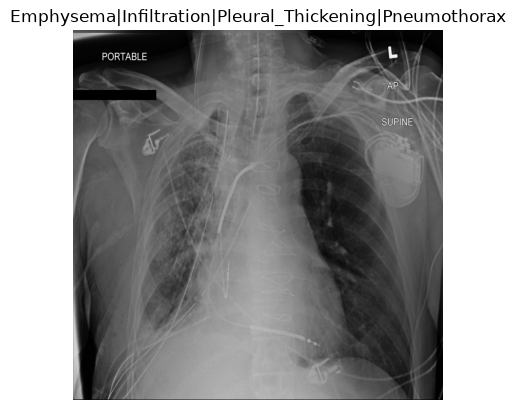

In [1]:
from pathlib import Path

import os
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

repo_dir = Path.cwd()
repo_dir = repo_dir.parent

# Data directory containing the NIH Chest X-ray dataset
data_dir = Path(
    os.environ.get(
        "XRAY_DATA_DIR",
        "/media/volume/xray-data/nih-chest-xrays",
    )
).expanduser()

# Read the sample labels CSV file, ensuring that the "Patient ID" column is read as a string
labels = pd.read_csv(
    repo_dir / "data/sample_labels.csv",
    dtype={"Patient ID": str},
)

# All png image paths from the dataset directory, recursively
image_paths = list(data_dir.rglob("*.png"))

# Check for duplicate PNG filenames in the dataset directory
images = {path.name: path for path in image_paths}
if len(images) != len(image_paths):
    raise ValueError("Duplicate PNG filenames found in the dataset directory.")

# Map the "Image Index" column in the labels DataFrame to the corresponding image paths
labels["image_path"] = labels["Image Index"].map(images)
missing = labels["image_path"].isna().sum()
if missing:
    raise FileNotFoundError(f"{missing:,} labeled images are missing under {data_dir}")

print(f"Matched {len(labels):,} images from {labels['Patient ID'].nunique():,} patients.")

# Display the first image in the dataset along with its corresponding label
row = labels.iloc[0]
with Image.open(row["image_path"]) as image:
    plt.imshow(image.convert("L"), cmap="gray")
plt.title(row["Finding Labels"])
plt.axis("off")
plt.show()

In [2]:
# Check that image path file name and image index file name match
labels['image_path'].astype(str).str[-16:].equals(labels["Image Index"])

True

## Encode Finding Labels And Split by Patient

Below, we:

* create a column for each of the 14 findings that has the value `1` if the image has that finding, and `0` else. The `No Findings` finding is just all finding variables set to `0`. These columns are stored in `targets`
* Split the image data into 70% training, 30% testing, dividing by patient rather than just image number
* Output size of training, validation, and test set, as well as the amount of each finding in those sets.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

# Create column for each finding label, excluding "No Finding"
targets = labels["Finding Labels"].str.get_dummies(sep="|").drop(columns="No Finding")

# Used for grouping by patients
patients = labels["Patient ID"]

# Hold out 30% of patients, divide those patients equally
seed = 1
train_idx, held_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    .split(targets, groups=patients)
)
val_pos, test_pos = next(
    GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    .split(targets.iloc[held_idx], groups=patients.iloc[held_idx])
)

splits = {
    "train": train_idx,
    "validation": held_idx[val_pos],
    "test": held_idx[test_pos],
}

positive_patients = pd.DataFrame({
    split: targets.iloc[idx].groupby(patients.iloc[idx]).max().sum()
    for split, idx in splits.items()
})

print({split: len(idx) for split, idx in splits.items()})
display(positive_patients.sort_values("test"))

{'train': 3905, 'validation': 846, 'test': 855}


,train,validation,test
Hernia,8,2,3
Pneumonia,40,11,8
Emphysema,84,17,13
Edema,81,15,13
Fibrosis,52,13,15
Cardiomegaly,89,17,20
Pleural_Thickening,113,27,24
Pneumothorax,171,26,29
Consolidation,137,28,33
Mass,176,50,35


## Try one batch through frozen resnet-18

Below we,

* Set up the frozen ResNet-18 model
* Download its pre-trained weights
* Find the weights' preprocessing resizing function
* Center-crop and normalize each image
* Try running resnet-18 through one batch to ensure it runs correctly

In [7]:
import numpy as np
import torch
from PIL import Image
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18

weights = ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()

backbone = resnet18(weights=weights)
backbone.fc = nn.Identity()  # Return the features before the ImageNet classifier.
backbone.eval()

def extract_batch(image_paths):
    inputs = []
    for path in image_paths:
        with Image.open(path) as image:
            inputs.append(preprocess(image.convert("RGB")))

    with torch.inference_mode():
        return backbone(torch.stack(inputs)).numpy()

preview = extract_batch(labels.iloc[splits["train"][:8]]["image_path"])
assert preview.shape == (8, 512)
assert np.isfinite(preview).all()
print("Feature shape:", preview.shape)

Feature shape: (8, 512)


Below, we run the code cell once to extract and save the full feature matrix.

In [ ]:
# from time import perf_counter

# # If not working on the cloud use the line of code below
# # volume_dir = Path("path/to/xray-data")

# volume_dir = Path("/media/volume/xray-data")

# cache_dir = volume_dir / "features"
# cache_dir.mkdir(exist_ok=True)
# cache_path = cache_dir / "resnet18_imagenet1k_v1.npz"

# image_paths = labels["image_path"].tolist()
# batch_size = 8
# features = np.empty((len(image_paths), 512), dtype=np.float32)
# started = perf_counter()

# for start in range(0, len(image_paths), batch_size):
#     stop = min(start + batch_size, len(image_paths))
#     features[start:stop] = extract_batch(image_paths[start:stop])

#     if stop == 128:
#         estimated_minutes = (perf_counter() - started) * len(image_paths) / stop / 60
#         print(f"Estimated total extraction time: {estimated_minutes:.1f} minutes")

# assert np.isfinite(features).all()
# np.savez_compressed(
#     cache_path,
#     features=features,
#     image_ids=labels["Image Index"].to_numpy(dtype=str),
# )
# print(f"Saved {features.shape} to {cache_path}")

Estimated total extraction time: 5.3 minutes
Saved (5606, 512) to /media/volume/xray-data/features/resnet18_imagenet1k_v1.npz


The code chunk below can be used after running the above code chunk once to retrieve the model features.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd

cache_path = Path(
    "/media/volume/xray-data/features/resnet18_imagenet1k_v1.npz"
)

with np.load(cache_path, allow_pickle=False) as cache:
    cached_features = cache["features"]
    cached_ids = pd.Index(cache["image_ids"])

# Align cached rows to the current label table by filename.
if not cached_ids.is_unique:
    raise ValueError("The feature cache contains duplicate image IDs.")

positions = cached_ids.get_indexer(labels["Image Index"])
if (positions < 0).any():
    raise ValueError(f"{(positions < 0).sum()} labeled images are missing from the cache.")

X = cached_features[positions]

print("Feature matrix:", X.shape)
display(pd.DataFrame(X[:5, :5], index=labels["Image Index"].iloc[:5]))

Feature matrix: (5606, 512)


,0,1,2,3,4
Image Index,,,,,
00000013_005.png,0.549791,1.371997,0.106670,4.269182,1.552082
00000013_026.png,1.063586,0.846069,0.165006,4.111802,0.806530
00000017_001.png,0.893348,1.651078,0.448978,4.752269,0.535078
00000030_001.png,0.670123,0.792079,0.144938,3.793266,0.707858
00000032_001.png,0.844191,0.769019,0.108819,3.147011,0.517941


In [7]:
train_idx = splits["train"]
X_train = X[train_idx]
y_train = targets.iloc[train_idx]

print("Training features:", X_train.shape)  # (3905, 512)
print("Training targets:", y_train.shape)   # (3905, 14)

Training features: (3905, 512)
Training targets: (3905, 14)


## Fit and Evaluate

Here, we

* Use MLflow to keep track of our models, their statistics and parameters

In [9]:
# If MLflow not installed, run this code chunk
# %pip install mlflow

In [11]:
import mlflow
import mlflow.sklearn

# If data saved locally, not on the cloud then use the line of code below
# volume = Path("path/to/xray-data")

volume = Path("/media/volume/xray-data")
if not volume.is_mount():
    raise RuntimeError(f"Mount the Jetstream volume at {volume} first.")

tracking_dir = volume / "mlflow"
tracking_dir.mkdir(exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{tracking_dir / 'tracking.db'}")
experiment_name = "nih-xray-multilabel"

if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(
        experiment_name,
        artifact_location=(tracking_dir / "artifacts").as_uri(),
    )

mlflow.set_experiment(experiment_name)

2026/11/25 00:28:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/25 00:28:34 INFO mlflow.store.db.utils: Updating database tables


<Experiment: artifact_location='file:///media/volume/xray-data/mlflow/artifacts', creation_time=1795566519422, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795566519422, lifecycle_stage='active', name='nih-xray-multilabel', tags={}, trace_location=None, workspace='default'>

Here we fit, score and save our baseline ResNet model.

Additionally, we produce a table that has the following stats for each finding:

* `val_prevalence`: Validation set prevalence. The proportion of images in the validation set that have the finding/label active/positive. A naive model would be expected to have this average precision (AP) score.
* `train_ap`: Training set Average Precision. The area under the Precision-Recall curve (PR-AUC) on the training set.
* `val_ap`: Validation set Average Precision. The area under the Precision-Recall curve (PR-AUC) on the validation set.

Typically, if AP is about the same as the validation prevalence, the model is performing no better than a naive model. If validation AP is greater than the prevalence, then the model has predictive power. As validation AP approaches 1, the model improves, with 1 being a perfect score.

A massive difference between training AP and validation AP typically signifies overfitting.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

val_idx = splits["validation"]
X_val = X[val_idx]
y_val = targets.iloc[val_idx]

baseline = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(
        LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
    ),
)

with mlflow.start_run(run_name="resnet18-logreg-baseline") as run:
    mlflow.log_params({
        "backbone": "resnet18",
        "weights": "IMAGENET1K_V1",
        "split_seed": seed,
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 1000,
        "class_weight": "none",
        "feature_scaling": "StandardScaler",
    })

    baseline.fit(X_train, y_train)

    results = pd.DataFrame({
        "finding": y_train.columns.tolist(),
        "train_positives": y_train.sum().to_numpy(),
        "val_positives": y_val.sum().to_numpy(),
        "val_prevalence": y_val.mean().to_numpy(),
        "train_ap": average_precision_score(
            y_train, baseline.predict_proba(X_train), average=None
        ),
        "val_ap": average_precision_score(
            y_val, baseline.predict_proba(X_val), average=None
        ),
    })
    results["train_val_gap"] = results["train_ap"] - results["val_ap"]

    mlflow.log_metrics({
        "train_macro_ap": float(results["train_ap"].mean()),
        "val_macro_ap": float(results["val_ap"].mean()),
    })
    for row in results.itertuples(index=False):
        label = row.finding.lower()
        mlflow.log_metric(f"train_ap_{label}", float(row.train_ap))
        mlflow.log_metric(f"val_ap_{label}", float(row.val_ap))

    mlflow.log_text(results.to_csv(index=False), "per_label_metrics.csv")
    mlflow.log_dict({"label_order": y_train.columns.tolist()}, "labels.json")
    model_info = mlflow.sklearn.log_model(baseline, name="classifier")

print("MLflow run ID:", run.info.run_id)
print("Saved model URI:", model_info.model_uri)
display(results.sort_values("val_ap", ascending=False).round(4))

2026/11/25 00:30:52 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0+cpu' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


MLflow run ID: 17321dd7ba7b43b98a947761000ffba6
Saved model URI: models:/m-2dd64f3e36e643fead98471f019cea30


,finding,train_positives,val_positives,val_prevalence,train_ap,val_ap,train_val_gap
8,Infiltration,666,145,0.1714,0.5543,0.2402,0.3141
4,Effusion,445,96,0.1135,0.6629,0.2187,0.4441
7,Hernia,8,2,0.0024,1.0000,0.1694,0.8306
0,Atelectasis,350,65,0.0768,0.6279,0.1673,0.4606
13,Pneumothorax,205,30,0.0355,0.8318,0.1074,0.7244
5,Emphysema,95,18,0.0213,1.0000,0.1016,0.8984
9,Mass,186,61,0.0721,0.7307,0.0923,0.6384
10,Nodule,212,51,0.0603,0.6137,0.0748,0.5389
11,Pleural_Thickening,123,27,0.0319,0.8342,0.0710,0.7633
2,Consolidation,159,30,0.0355,0.8578,0.0571,0.8007


In [17]:
mlflow.sklearn.load_model(model_info.model_uri)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('onevsrestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](14,)","[ 0, 1, 2,...,11,12,13]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,512
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


`train_val_gap` is huge for all findings which implies our model is overfitting. We can adjust parameter `c` for higher regularization to prevent overfitting. which we do in the next two code chunks.

In [18]:
from sklearn.base import clone

comparison_tables = [results.assign(C=1.0)]
models_by_c = {1.0: baseline}

for c in [0.001, 0.01, 0.1, 10.0]:
    model = clone(baseline).set_params(
        onevsrestclassifier__estimator__C=c
    )

    with mlflow.start_run(run_name=f"resnet18-logreg-C-{c}"):
        mlflow.log_params({
            "backbone": "resnet18",
            "weights": "IMAGENET1K_V1",
            "split_seed": seed,
            "C": c,
            "solver": "lbfgs",
            "max_iter": 1000,
            "class_weight": "none",
            "feature_scaling": "StandardScaler",
        })
        model.fit(X_train, y_train)

        scores = results[
            ["finding", "train_positives", "val_positives", "val_prevalence"]
        ].copy()
        scores["C"] = c
        scores["train_ap"] = average_precision_score(
            y_train, model.predict_proba(X_train), average=None
        )
        scores["val_ap"] = average_precision_score(
            y_val, model.predict_proba(X_val), average=None
        )
        scores["train_val_gap"] = scores["train_ap"] - scores["val_ap"]

        metrics = {
            "train_macro_ap": float(scores["train_ap"].mean()),
            "val_macro_ap": float(scores["val_ap"].mean()),
        }
        for row in scores.itertuples(index=False):
            label = row.finding.lower()
            metrics[f"train_ap_{label}"] = float(row.train_ap)
            metrics[f"val_ap_{label}"] = float(row.val_ap)

        mlflow.log_metrics(metrics)
        mlflow.log_text(scores.to_csv(index=False), "per_label_metrics.csv")

    comparison_tables.append(scores)
    models_by_c[c] = model

tuning_results = pd.concat(comparison_tables, ignore_index=True)

summary = (
    tuning_results.groupby("C", as_index=False)
    .agg(
        train_macro_ap=("train_ap", "mean"),
        val_macro_ap=("val_ap", "mean"),
        mean_gap=("train_val_gap", "mean"),
    )
    .sort_values("val_macro_ap", ascending=False)
)

display(summary.round(4))
display(
    tuning_results.pivot(index="finding", columns="C", values="val_ap")
    .round(4)
)

,C,train_macro_ap,val_macro_ap,mean_gap
0,0.001,0.2442,0.1304,0.1138
1,0.010,0.4652,0.1269,0.3383
2,0.100,0.7307,0.1190,0.6117
3,1.000,0.8340,0.1029,0.7311
4,10.000,0.8672,0.1009,0.7663


C,0.001,0.010,0.100,1.000,10.000
finding,,,,,
Atelectasis,0.1908,0.1937,0.1708,0.1673,0.1626
Cardiomegaly,0.0577,0.0549,0.0536,0.0504,0.0511
Consolidation,0.0799,0.0832,0.0649,0.0571,0.0646
Edema,0.1113,0.1073,0.0642,0.0545,0.0467
Effusion,0.3056,0.2857,0.2474,0.2187,0.2128
Emphysema,0.0756,0.1254,0.1148,0.1016,0.1037
Fibrosis,0.0439,0.0356,0.0249,0.0230,0.0235
Hernia,0.0573,0.0944,0.2560,0.1694,0.1687
Infiltration,0.2735,0.2649,0.2469,0.2402,0.2399


In [19]:
for c in [0.0001, 0.0003, 0.003]:
    model = clone(baseline).set_params(
        onevsrestclassifier__estimator__C=c
    )

    with mlflow.start_run(run_name=f"resnet18-logreg-C-{c}"):
        mlflow.log_params({
            "backbone": "resnet18",
            "weights": "IMAGENET1K_V1",
            "split_seed": seed,
            "C": c,
            "solver": "lbfgs",
            "max_iter": 1000,
            "class_weight": "none",
            "feature_scaling": "StandardScaler",
        })
        model.fit(X_train, y_train)

        scores = results[
            ["finding", "train_positives", "val_positives", "val_prevalence"]
        ].copy()
        scores["C"] = c
        scores["train_ap"] = average_precision_score(
            y_train, model.predict_proba(X_train), average=None
        )
        scores["val_ap"] = average_precision_score(
            y_val, model.predict_proba(X_val), average=None
        )
        scores["train_val_gap"] = scores["train_ap"] - scores["val_ap"]

        metrics = {
            "train_macro_ap": float(scores["train_ap"].mean()),
            "val_macro_ap": float(scores["val_ap"].mean()),
        }
        for row in scores.itertuples(index=False):
            label = row.finding.lower()
            metrics[f"train_ap_{label}"] = float(row.train_ap)
            metrics[f"val_ap_{label}"] = float(row.val_ap)

        mlflow.log_metrics(metrics)
        mlflow.log_text(scores.to_csv(index=False), "per_label_metrics.csv")

    comparison_tables.append(scores)
    models_by_c[c] = model

tuning_results = pd.concat(comparison_tables, ignore_index=True)

summary = (
    tuning_results.groupby("C", as_index=False)
    .agg(
        train_macro_ap=("train_ap", "mean"),
        val_macro_ap=("val_ap", "mean"),
        mean_gap=("train_val_gap", "mean"),
    )
    .sort_values("val_macro_ap", ascending=False)
)

display(summary.round(4))
display(
    tuning_results.pivot(index="finding", columns="C", values="val_ap")
    .round(4)
)

,C,train_macro_ap,val_macro_ap,mean_gap
3,0.0030,0.3265,0.1322,0.1943
2,0.0010,0.2442,0.1304,0.1138
4,0.0100,0.4652,0.1269,0.3383
1,0.0003,0.1922,0.1242,0.0680
0,0.0001,0.1674,0.1198,0.0476
5,0.1000,0.7307,0.1190,0.6117
6,1.0000,0.8340,0.1029,0.7311
7,10.0000,0.8672,0.1009,0.7663


C,0.0001,0.0003,0.0010,0.0030,0.0100,0.1000,1.0000,10.0000
finding,,,,,,,,
Atelectasis,0.1630,0.1775,0.1908,0.1949,0.1937,0.1708,0.1673,0.1626
Cardiomegaly,0.0530,0.0542,0.0577,0.0559,0.0549,0.0536,0.0504,0.0511
Consolidation,0.0715,0.0747,0.0799,0.0845,0.0832,0.0649,0.0571,0.0646
Edema,0.0833,0.0869,0.1113,0.1108,0.1073,0.0642,0.0545,0.0467
Effusion,0.2973,0.3086,0.3056,0.2991,0.2857,0.2474,0.2187,0.2128
Emphysema,0.0588,0.0638,0.0756,0.1011,0.1254,0.1148,0.1016,0.1037
Fibrosis,0.0458,0.0455,0.0439,0.0419,0.0356,0.0249,0.0230,0.0235
Hernia,0.0592,0.0636,0.0573,0.0712,0.0944,0.2560,0.1694,0.1687
Infiltration,0.2535,0.2625,0.2735,0.2714,0.2649,0.2469,0.2402,0.2399


Our best choice for `c` is 0.003 by Validation set AP and significantly reduces the training and validation AP gap.

Below we use this model as the final model and fit it to our testing data.

In [21]:
selected_c = 0.003
selected_model = models_by_c[selected_c]
test_idx = splits["test"]

X_test = X[test_idx]
y_test = targets.iloc[test_idx]
test_patients = labels.iloc[test_idx]["Patient ID"].to_numpy()

test_scores = selected_model.predict_proba(X_test)
positive_patients = y_test.groupby(test_patients).max().sum()

test_results = pd.DataFrame({
    "finding": y_test.columns.tolist(),
    "test_positive_images": y_test.sum().to_numpy(),
    "test_positive_patients": positive_patients.to_numpy(),
    "test_prevalence": y_test.mean().to_numpy(),
    "test_ap": average_precision_score(y_test, test_scores, average=None),
})

split_manifest = pd.concat(
    [
        labels.iloc[idx][["Image Index", "Patient ID"]].assign(split=split_name)
        for split_name, idx in splits.items()
    ],
    ignore_index=True,
)

with mlflow.start_run(run_name="resnet18-logreg-selected-test") as run:
    mlflow.log_params({
        "backbone": "resnet18",
        "weights": "IMAGENET1K_V1",
        "C": selected_c,
        "class_weight": "none",
        "split_seed": seed,
        "selection_metric": "validation_macro_ap",
        "test_images": len(y_test),
    })
    mlflow.log_metric("test_macro_ap", float(test_results["test_ap"].mean()))
    for row in test_results.itertuples(index=False):
        mlflow.log_metric(f"test_ap_{row.finding.lower()}", float(row.test_ap))

    mlflow.log_text(test_results.to_csv(index=False), "test_metrics.csv")
    mlflow.log_text(split_manifest.to_csv(index=False), "split_manifest.csv")
    mlflow.log_dict({"label_order": y_test.columns.tolist()}, "labels.json")
    model_info = mlflow.sklearn.log_model(selected_model, name="classifier")

print("Test macro AP:", round(test_results["test_ap"].mean(), 4))
print("Test macro prevalence:", round(test_results["test_prevalence"].mean(), 4))
print("MLflow run ID:", run.info.run_id)
print("Saved model URI:", model_info.model_uri)
display(test_results.sort_values("test_ap", ascending=False).round(4))

2026/11/25 01:04:44 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0+cpu' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


Test macro AP: 0.1394
Test macro prevalence: 0.0518
MLflow run ID: 3a2bfaf1dd014a04845bbf1dc581bfec
Saved model URI: models:/m-9622eb7cb39443b191a2a0b96158386a


,finding,test_positive_images,test_positive_patients,test_prevalence,test_ap
4,Effusion,103,88,0.1205,0.2940
8,Infiltration,156,135,0.1825,0.2816
0,Atelectasis,93,83,0.1088,0.2332
3,Edema,15,13,0.0175,0.2264
13,Pneumothorax,36,29,0.0421,0.2046
9,Mass,37,35,0.0433,0.1619
1,Cardiomegaly,24,20,0.0281,0.1213
10,Nodule,50,46,0.0585,0.0908
2,Consolidation,37,33,0.0433,0.0907
11,Pleural_Thickening,26,24,0.0304,0.0675


The test macro average precision (AP) is 0.1394, which is significantly higher than the test macro average prevalence baseline of 0.0518. All 14 findings scored above their own prevalance baseline in this split.

Effusion has the highest absolute test AP, with Edema and Pneumothorax showing the most substantial gain over its prevalence baseline. It appears that this model is best at identifying Effusion, Edema, and Pneumothorax.

For the other findings, there's some varying level of improvement from the baseline prevalence in the test AP. Please note that while we have displayed the results for all finding labels, some findings (most notably, hernia) have a very small sample size for positive images in the testing set, so we have little basis to judge how reliably our model generalizes for that finding.